<a href="https://colab.research.google.com/github/prannav-vg/VLM_fun/blob/main/Anomalies_Testing19Videos_VLM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/content/Testing_No 100%[===================>]   4.34G  64.1MB/s    in 91s     
Normal zip: 4.66 GB
Official normal test videos in zip: 150
Testing 19 normal videos (first 60s of each)

=== Normal_Videos_003_x264.mp4 | 94s long, testing 60s ===
   0.0s -   10.0s | ANOMALY | conf 0.99 | Dog walking towards the camera
  10.0s -   20.0s | ANOMALY | conf 0.99 | Dog walking towards the camera
  20.0s -   30.0s | ANOMALY | conf 0.99 | Dog running towards the camera
  30.0s -   40.0s | ANOMALY | conf 0.99 | Dog walking towards the camera
  40.0s -   50.0s | ANOMALY | conf 0.80 | Dog walking towards the camera
  50.0s -   60.0s | ANOMALY | conf 0.80 | Dog carrying a yellow bucket
=== Normal_Videos_006_x264.mp4 | 15s long, testing 15s ===
   0.0s -   10.0s | ANOMALY | conf 0.80 | A car is driving in the opposite direction of the traffic.
  10.0s -   15.0s | ANOMALY | conf 0.80 | A car is driving erratically and suddenly stops.
=== Normal_Videos_010_x264.mp4 | 35s long, testing 35s ===
   0.0s -

,video,tested_s,chunks,false_alarms,false_alarm_%,model_said
0,Normal_Videos_003_x264.mp4,60,6,6,100,Dog carrying a yellow bucket; Dog running towa...
1,Normal_Videos_006_x264.mp4,15,2,2,100,A car is driving erratically and suddenly stop...
2,Normal_Videos_010_x264.mp4,35,4,4,100,A person is seen walking into the room and the...
3,Normal_Videos_014_x264.mp4,50,5,0,0,-
4,Normal_Videos_015_x264.mp4,16,2,2,100,A person is standing on a construction platfor...
5,Normal_Videos_018_x264.mp4,39,4,0,0,-
6,Normal_Videos_019_x264.mp4,60,6,5,83,A man in an orange vest walks into a store and...
7,Normal_Videos_024_x264.mp4,36,4,4,100,A man in a white shirt is walking towards the ...
8,Normal_Videos_025_x264.mp4,20,2,1,50,A person is seen walking into the room and the...
9,Normal_Videos_027_x264.mp4,60,6,4,67,A man in a hat is walking with a bag in a room...


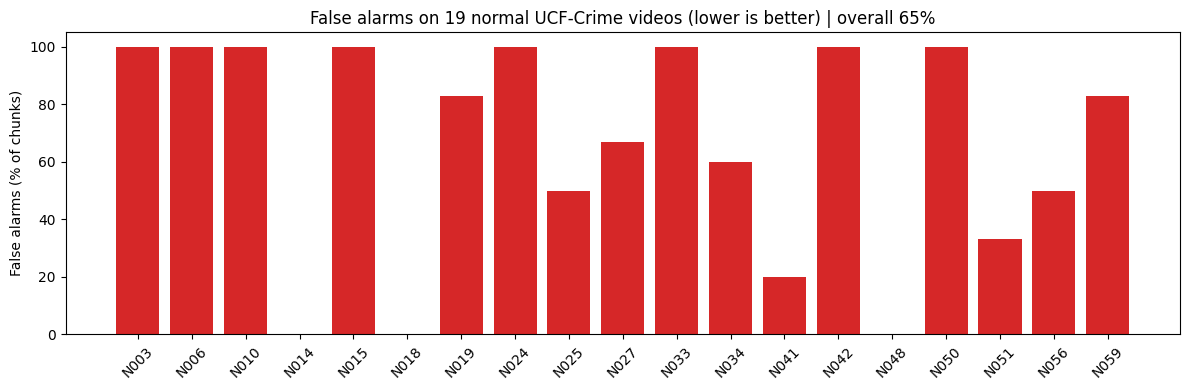

Saved: ucf_normal_results.png, ucf_normal_summary.csv, ucf_normal_chunks.csv


In [4]:
import os, re, zipfile, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NORMAL_LINK = "https://www.dropbox.com/scl/fo/2aczdnx37hxvcfdo4rq4q/AHTTsM4LmY3lQdqO9mMBjFw/Testing_Normal_Videos.zip?rlkey=5bg7mxxbq46t7aujfch46dlvz&dl=0"
NORMAL_ZIP = "/content/Testing_Normal_Videos.zip"
NORMAL_DIR = "/content/ucf_normal"
N_VIDEOS = 19
MAX_SECONDS = 60

NORMAL_TEST_IDS = "003,006,010,014,015,018,019,024,025,027,033,034,041,042,048,050,051,056,059,063,067,070,100,129,150,168,175,182,189,196,203,210,217,224,246,247,248,251,289,310,312,317,345,352,360,365,401,417,439,452,453,478,576,597,603,606,621,634,641,656,686,696,702,704,710,717,722,725,745,758,778,780,781,782,783,798,801,828,831,866,867,868,869,870,871,872,873,874,875,876,877,878,879,880,881,882,883,884,885,886,887,888,889,890,891,892,893,894,895,896,897,898,899,900,901,902,903,904,905,906,907,908,909,910,911,912,913,914,915,923,924,925,926,927,928,929,930,931,932,933,934,935,936,937,938,939,940,941,943,944"
normal_test_names = {f"Normal_Videos_{i}_x264.mp4" for i in NORMAL_TEST_IDS.split(",")}

if not os.path.exists(NORMAL_ZIP) or os.path.getsize(NORMAL_ZIP) < 1e8:
    link = NORMAL_LINK.replace("dl=0", "dl=1")
    !wget -q --show-progress -O "$NORMAL_ZIP" "$link"
print(f"Normal zip: {os.path.getsize(NORMAL_ZIP) / 1e9:.2f} GB")

os.makedirs(NORMAL_DIR, exist_ok=True)
with zipfile.ZipFile(NORMAL_ZIP) as z:
    members = [m for m in z.namelist() if os.path.basename(m) in normal_test_names]
    print(f"Official normal test videos in zip: {len(members)}")
    for m in sorted(members)[:N_VIDEOS]:
        out = os.path.join(NORMAL_DIR, os.path.basename(m))
        if not os.path.exists(out):
            with z.open(m) as src, open(out, "wb") as dst:
                shutil.copyfileobj(src, dst)
normal_videos = sorted(f for f in os.listdir(NORMAL_DIR) if f.endswith(".mp4"))[:N_VIDEOS]
print(f"Testing {len(normal_videos)} normal videos (first {MAX_SECONDS}s of each)\n")

normal_rows, normal_chunks = [], []
for name in normal_videos:
    path = os.path.join(NORMAL_DIR, name)
    fps, n_frames = video_info(path)
    full_len = n_frames / fps
    duration = min(full_len, MAX_SECONDS)
    print(f"=== {name} | {full_len:.0f}s long, testing {duration:.0f}s ===")
    results = detect_anomalies(path, duration, CHUNK_SECONDS, threshold=THRESHOLD)
    flagged = [r for r in results if r["anomaly"] and r["confidence"] >= THRESHOLD]
    for r in results:
        normal_chunks.append({"video": name, **r})
    normal_rows.append({
        "video": name,
        "tested_s": round(duration),
        "chunks": len(results),
        "false_alarms": len(flagged),
        "false_alarm_%": round(100 * len(flagged) / max(len(results), 1)),
        "model_said": "; ".join(sorted({r["event"] for r in flagged}))[:80] or "-",
    })

normal_summary = pd.DataFrame(normal_rows)
total_chunks = normal_summary["chunks"].sum()
total_fa = normal_summary["false_alarms"].sum()
clean_videos = (normal_summary["false_alarms"] == 0).sum()

print("\n" + "=" * 70)
print(f"NORMAL VIDEOS TEST | {len(normal_videos)} official UCF-Crime normal test videos")
print(f"Chunks tested: {total_chunks} (10s each, first {MAX_SECONDS}s per video)")
print(f"False alarms: {total_fa} of {total_chunks} chunks ({100 * total_fa / total_chunks:.0f}%)")
print(f"Correctly normal (specificity): {100 * (total_chunks - total_fa) / total_chunks:.0f}%")
print(f"Videos with zero false alarms: {clean_videos} of {len(normal_videos)}")
print("=" * 70)
display(normal_summary)

plt.figure(figsize=(12, 4))
plt.bar(range(len(normal_summary)), normal_summary["false_alarm_%"], color="tab:red")
plt.xticks(range(len(normal_summary)), [v.replace("_x264.mp4", "").replace("Normal_Videos_", "N") for v in normal_summary["video"]], rotation=45)
plt.ylabel("False alarms (% of chunks)")
plt.ylim(0, 105)
plt.title(f"False alarms on {len(normal_videos)} normal UCF-Crime videos (lower is better) | overall {100 * total_fa / total_chunks:.0f}%")
plt.tight_layout()
plt.savefig("/content/ucf_normal_results.png", dpi=150, bbox_inches="tight")
plt.show()

normal_summary.to_csv("/content/ucf_normal_summary.csv", index=False)
pd.DataFrame(normal_chunks).to_csv("/content/ucf_normal_chunks.csv", index=False)
print("Saved: ucf_normal_results.png, ucf_normal_summary.csv, ucf_normal_chunks.csv")

Total chunks: 128  (anomalous: 16, normal: 112)
Caught (TP): 16 | Missed (FN): 0 | False alarms (FP): 78 | Correct normal (TN): 34
Precision:   0.17
Recall:      1.00
F1 score:    0.29
Specificity: 0.30  (share of normal chunks correctly called normal)


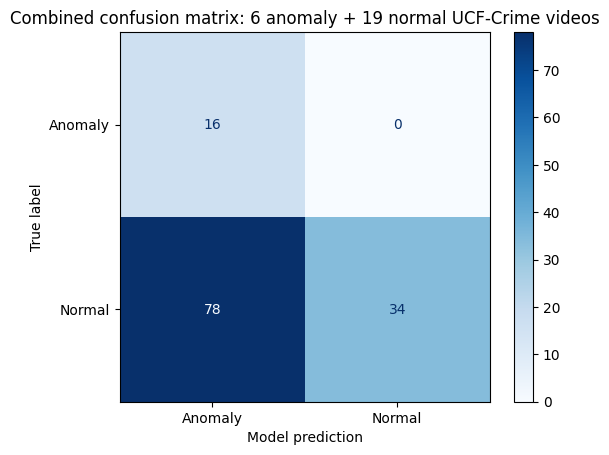

In [5]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score

y_true, y_pred = [], []

for name in videos:
    fps, _ = video_info(os.path.join(DATA_DIR, name))
    true_secs = [(s / fps, e / fps) for s, e in annotations[name]["intervals"]]
    for r in chunk_rows:
        if r["video"] == name:
            y_true.append(int(any(r["start"] < te and r["end"] > ts for ts, te in true_secs)))
            y_pred.append(int(r["anomaly"] and r["confidence"] >= THRESHOLD))

for r in normal_chunks:
    y_true.append(0)
    y_pred.append(int(r["anomaly"] and r["confidence"] >= THRESHOLD))

cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
tp, fn, fp, tn = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print(f"Total chunks: {len(y_true)}  (anomalous: {sum(y_true)}, normal: {len(y_true) - sum(y_true)})")
print(f"Caught (TP): {tp} | Missed (FN): {fn} | False alarms (FP): {fp} | Correct normal (TN): {tn}")
print(f"Precision:   {precision_score(y_true, y_pred, zero_division=0):.2f}")
print(f"Recall:      {recall_score(y_true, y_pred, zero_division=0):.2f}")
print(f"F1 score:    {f1_score(y_true, y_pred, zero_division=0):.2f}")
print(f"Specificity: {tn / (tn + fp):.2f}  (share of normal chunks correctly called normal)")

disp = ConfusionMatrixDisplay(cm, display_labels=["Anomaly", "Normal"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Combined confusion matrix: 6 anomaly + 19 normal UCF-Crime videos")
plt.xlabel("Model prediction")
plt.ylabel("True label")
plt.savefig("/content/ucf_confusion_matrix_combined.png", dpi=150, bbox_inches="tight")
plt.show()